# ECG-Based Atrial Fibrillation Detection Using the PhysioNet 2017 Dataset

This notebook uses the **PhysioNet/CinC Challenge 2017 dataset**, which contains **8,528 single-lead ECG recordings** collected using the AliveCor device.

The dataset includes:
- **Sampling rate:** 300 Hz
- **Signal duration:** Approximately 9.05 - 60.95 seconds
- **Signal type:** Single-lead ECG (1D time-series data)
- **File format:** MATLAB (`.mat`) files
- **Labels:** Provided in `REFERENCE.csv` - version 2


| ECG Type | Label |
|:---------|-----------:|
| Normal | N |
| Atrial Fibrillation | A |
| Other Rhythm | O |
| Noisy | ~ |



In [ ]:
# Install dependencies
!pip install numpy pandas scipy matplotlib scikit-learn wfdb torch

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from scipy.io import loadmat
from collections import Counter
from sklearn.preprocessing import scale

## 1. Dataset Loading
Load the PhysioNet/CinC Challenge 2017 dataset and examine its basic structure before preprocessing.


In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')
data_dir = Path(
    "/content/drive/MyDrive/CMPE 257/training2017/training2017")

print("Folder exists:", data_dir.exists())
print("MAT files:", len(list(data_dir.glob("*.mat"))))
print("HEA files:", len(list(data_dir.glob("*.hea"))))
print("REFERENCE.csv exists:", (data_dir / "REFERENCE.csv").exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
MAT files: 8528
HEA files: 8528
REFERENCE.csv exists: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Read the ECG labels
labels = pd.read_csv(
    data_dir / "REFERENCE.csv",
    header=None,
    names=["record_id", "label"]
)
display(labels.head(10))
print("Total recordings:", len(labels))
print("\nClass distribution:")
print(labels["label"].value_counts())


,record_id,label
0,A00001,N
1,A00002,N
2,A00003,N
3,A00004,A
4,A00005,A
5,A00006,N
6,A00007,N
7,A00008,O
8,A00009,A
9,A00010,N


Total recordings: 8528

Class distribution:
label
N    5050
O    2456
A     738
~     284
Name: count, dtype: int64


In [ ]:
# Encode ECG class labels
label_map = {
    "N": 0,  # Normal
    "A": 1,  # AFib
    "O": 2,  # Other
    "~": 3   # Noisy
}

labels["class_id"] = labels["label"].map(label_map)
assert labels["class_id"].notna().all()
labels["class_id"] = labels["class_id"].astype(int)
display(labels.head())

,record_id,label,class_id
0,A00001,N,0
1,A00002,N,0
2,A00003,N,0
3,A00004,A,1
4,A00005,A,1


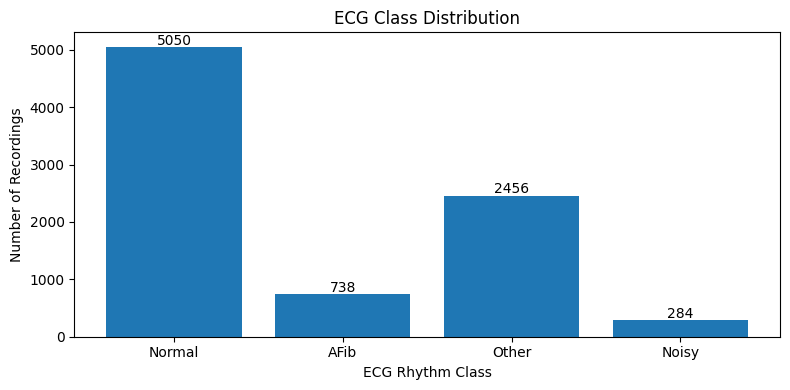

In [ ]:
#Visualize the number of ECG recordings in each class
class_names = {
    "N": "Normal",
    "A": "AFib",
    "O": "Other",
    "~": "Noisy"
}
counts = labels["label"].value_counts()
order = ["N", "A", "O", "~"]

plt.figure(figsize=(8, 4))

bars = plt.bar(
    [class_names[c] for c in order],
    [counts[c] for c in order]
)

plt.title("ECG Class Distribution")
plt.xlabel("ECG Rhythm Class")
plt.ylabel("Number of Recordings")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 40,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
plt.show()



## 2. Comparison of Original and Updated ECG Labels

Compare the original and revised annotations in the PhysioNet/CinC 2017 dataset to investigate changes in ECG rhythm classification. ]

The dataset provides two reference label files:

- **REFERENCE-original.csv:** Contains the initial ECG rhythm annotations.
- **REFERENCE.csv (V2):** Contains revised annotations following additional review.

In [ ]:
# Load and compare labels
import pandas as pd

original = pd.read_csv(
    data_dir / "REFERENCE-original.csv",
    header=None,
    names=["record_id", "original_label"]
)
updated = pd.read_csv(
    data_dir / "REFERENCE.csv",
    header=None,
    names=["record_id", "updated_label"]
)
# Match recordings by their unique identifiers
comparison = original.merge(
    updated,
    on="record_id",
    validate="one_to_one"
)
print("Original recordings:", len(original))
print("Updated recordings:", len(updated))
print("Matched recordings:", len(comparison))
display(comparison.head())

Original recordings: 8528
Updated recordings: 8528
Matched recordings: 8528


,record_id,original_label,updated_label
0,A00001,N,N
1,A00002,N,N
2,A00003,N,N
3,A00004,A,A
4,A00005,O,A


In [ ]:
# Compare class distributions
class_order = ["N", "A", "O", "~"]
original_counts = (
    original["original_label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)
updated_counts = (
    updated["updated_label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)
distribution = pd.DataFrame({
    "Original": original_counts,
    "Updated (V2)": updated_counts
})
distribution["Difference"] = (
    distribution["Updated (V2)"] - distribution["Original"]
)
display(distribution)

,Original,Updated (V2),Difference
N,5154,5050,-104
A,771,738,-33
O,2557,2456,-101
~,46,284,238


In [ ]:
# Identify recordings with changed labels
changed = comparison[
    comparison["original_label"] !=
    comparison["updated_label"]
].copy()

print("Total matched recordings:", len(comparison))
print("Recordings with changed labels:", len(changed))

print(
    "Percentage changed:",
    round(len(changed) / len(comparison) * 100, 2),
    "%"
)

display(changed.head(10))


Total matched recordings: 8528
Recordings with changed labels: 294
Percentage changed: 3.45 %


,record_id,original_label,updated_label
4,A00005,O,A
21,A00022,O,~
33,A00034,N,~
55,A00056,O,~
99,A00100,A,O
105,A00106,N,~
124,A00125,N,~
138,A00139,O,~
163,A00164,A,~
191,A00192,O,N


## 3. Exploratory Data Analysis (EDA)

Explore the raw ECG recordings to understand the dataset and identify potential issues before preprocessing.



In [ ]:
# Load a single ECG recording
record_id = "A00001"
mat_data = loadmat(data_dir / f"{record_id}.mat")
print("MAT keys:", mat_data.keys())
ecg = mat_data["val"].squeeze().astype(np.float32)

print("Signal shape:", ecg.shape)
print("Number of samples:", len(ecg))
print("Signal minimum:", ecg.min())
print("Signal maximum:", ecg.max())
print("Signal mean:", ecg.mean())
print("Signal standard deviation:", ecg.std())

MAT keys: dict_keys(['val'])
Signal shape: (9000,)
Number of samples: 9000
Signal minimum: -754.0
Signal maximum: 946.0
Signal mean: 18.569445
Signal standard deviation: 168.31798


In [ ]:
# Read the .hea file to check the ECG sampling rate, signal length, and format.
header_path = data_dir / f"{record_id}.hea"
with open(header_path, "r") as file:
    header_text = file.read()
print(header_text)


A00001 1 300 9000 05:05:15 1/05/2000 
A00001.mat 16+24 1000/mV 16 0 -127 0 0 ECG 



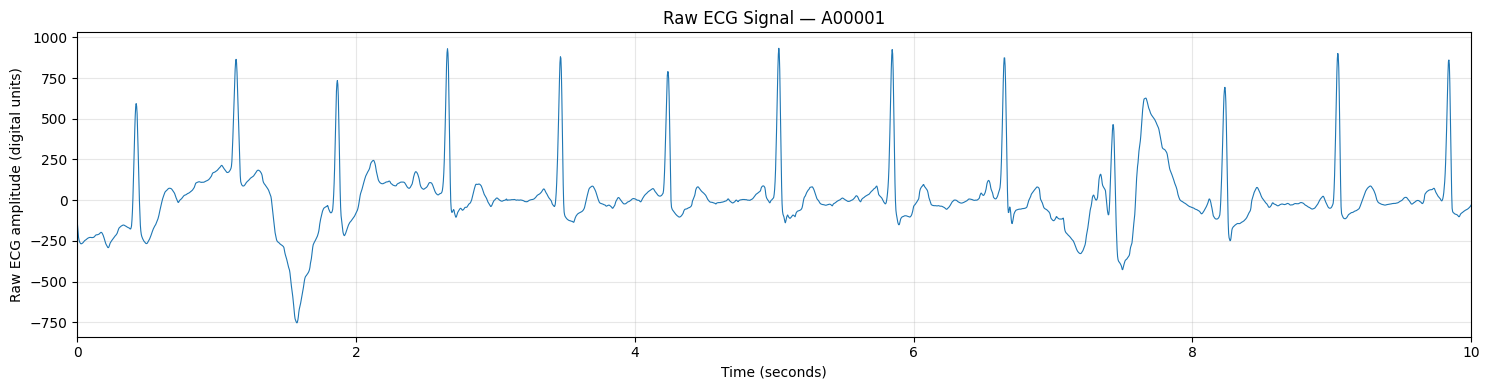

In [ ]:
# Visualize the ECG waveform
fs = 300
time = np.arange(len(ecg)) / fs
plt.figure(figsize=(15, 4))
plt.plot(time, ecg, linewidth=0.8)
plt.title(f"Raw ECG Signal — {record_id}")
plt.xlabel("Time (seconds)")
plt.ylabel("Raw ECG amplitude (digital units)")
plt.xlim(0, min(10, len(ecg) / fs))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Note:** We plot the first 10 seconds of the raw ECG signal to see the heartbeat patterns and changes in amplitude. The ECG signal (A00001) looks more like a Normal rhythm than AFib because most heartbeat peaks appear regularly spaced. However, there are some unusual amplitude changes around 1.5 and 7.5 seconds, which may be caused by noise or artifacts. We need to check the original label to confirm the rhythm.

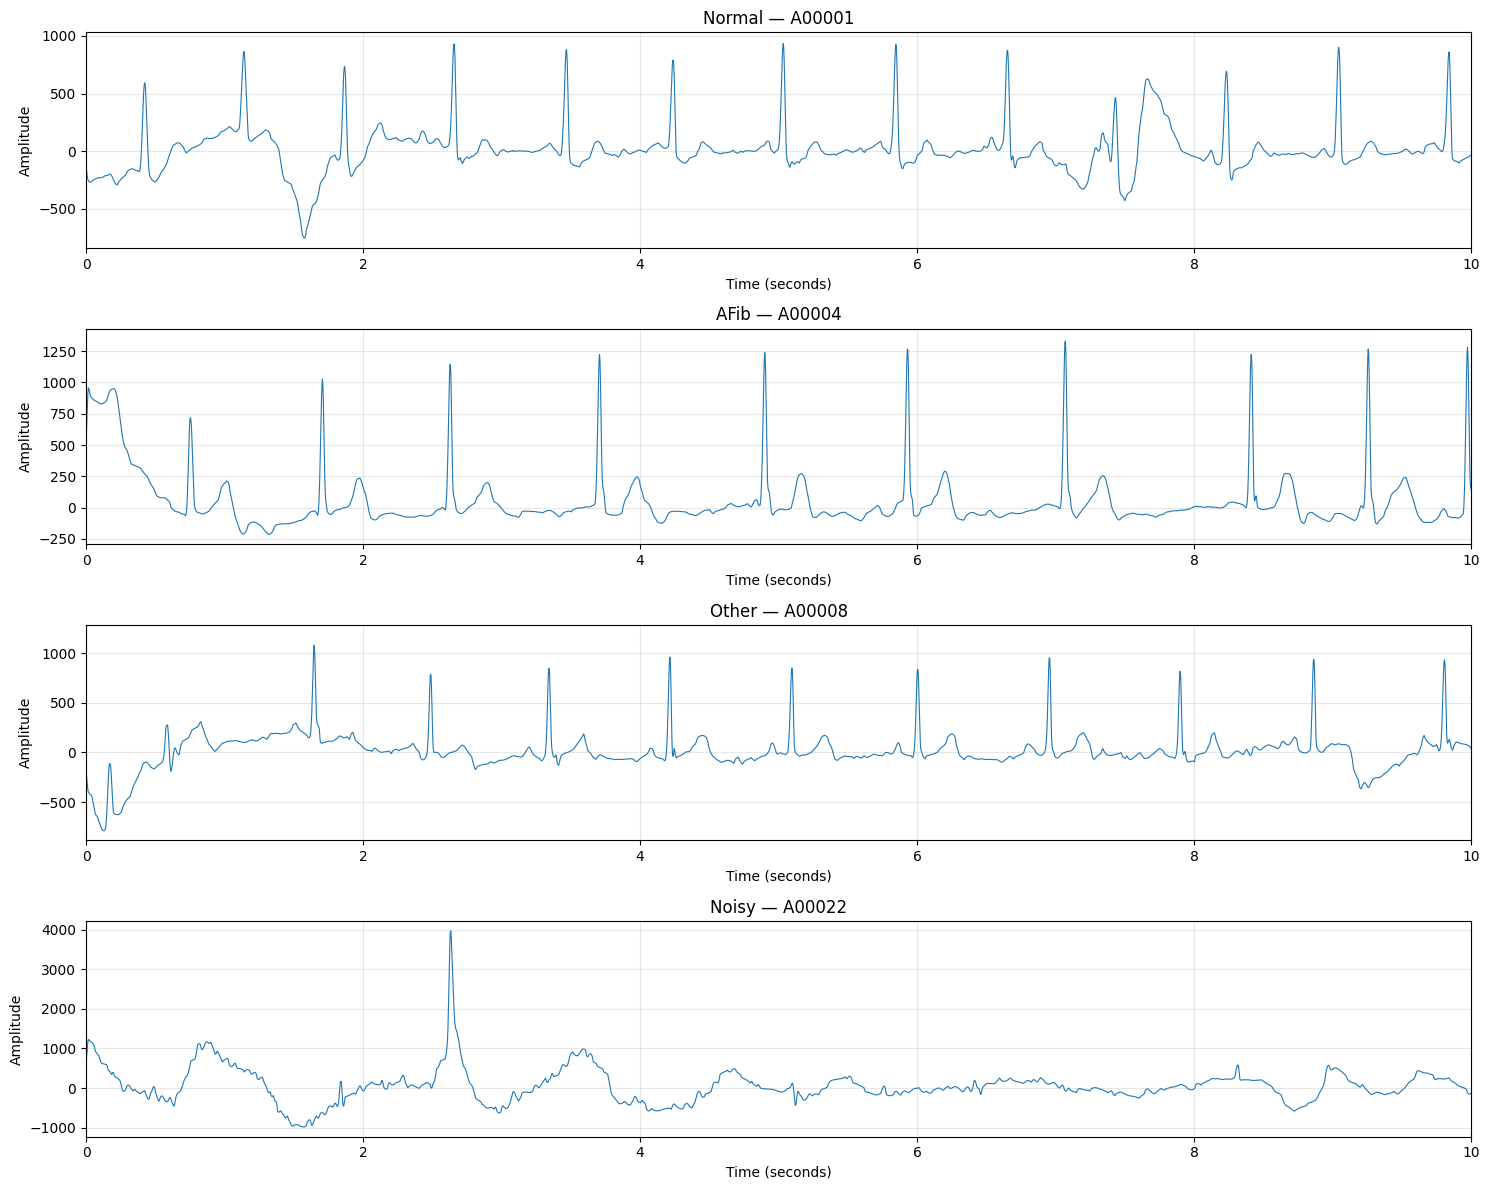

In [ ]:
# Visualize one recording from each class
fig, axes = plt.subplots(4, 1, figsize=(15, 12))

for ax, label in zip(axes, ["N", "A", "O", "~"]):
    record_id = labels.loc[
        labels["label"] == label, "record_id"
    ].iloc[0]
    signal = loadmat(
        data_dir / f"{record_id}.mat"
    )["val"].squeeze()
    time = np.arange(len(signal)) / 300
    ax.plot(time, signal, linewidth=0.8)
    ax.set_xlim(0, min(10, len(signal) / 300))
    ax.set_title(f"{class_names[label]} — {record_id}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Note:** The four ECG classes show different signal patterns. Normal (A00001) has mostly regular heartbeat peaks, with some unusual amplitude changes. AFib (A00004) shows changes in heartbeat intervals, although some peaks still look regular. Other (A00008) has a different waveform pattern, while Noisy (A00022) contains large fluctuations that make the heartbeats difficult to identify.

## 4. Data Validation and Cleaning

Check the ECG dataset for missing, duplicate, or corrupted recordings before preprocessing.

In [ ]:
# Check missing values and duplicate labels
print("Missing record IDs:", labels["record_id"].isna().sum())
print("Missing labels:", labels["label"].isna().sum())
print("Duplicate record IDs:", labels["record_id"].duplicated().sum())
print("Unexpected labels:", set(labels["label"]) - {"N", "A", "O", "~"})
print("Total labels:", len(labels))


Missing record IDs: 0
Missing labels: 0
Duplicate record IDs: 0
Unexpected labels: set()
Total labels: 8528


In [ ]:
# Check missing .mat and .hea file
missing_mat = []
missing_hea = []
for record_id in labels["record_id"]:
    if not (data_dir / f"{record_id}.mat").exists():
        missing_mat.append(record_id)
    if not (data_dir / f"{record_id}.hea").exists():
        missing_hea.append(record_id)

print("Missing MAT files:", len(missing_mat))
print("Missing HEA files:", len(missing_hea))
print("Examples of missing MAT:", missing_mat[:5])
print("Examples of missing HEA:", missing_hea[:5])

Missing MAT files: 0
Missing HEA files: 0
Examples of missing MAT: []
Examples of missing HEA: []


In [ ]:
# Check the quality of ECG signals throughout the dataset
from scipy.io import loadmat

quality_records = []

for _, row in labels.iterrows():
    record_id = row["record_id"]
    path = data_dir / f"{record_id}.mat"
    result = {
        "record_id": record_id,
        "label": row["label"],
        "status": "valid",
        "n_samples": np.nan,
        "duration_sec": np.nan,
        "mean": np.nan,
        "std": np.nan,
        "min": np.nan,
        "max": np.nan
    }
    try:
        signal = loadmat(path)["val"]
        signal = np.asarray(signal).squeeze()
        if signal.ndim != 1 or signal.size == 0:
            result["status"] = "invalid_shape"
        elif not np.isfinite(signal).all():
            result["status"] = "non_finite"
        else:
            result["n_samples"] = len(signal)
            result["duration_sec"] = len(signal) / 300
            result["mean"] = np.mean(signal)
            result["std"] = np.std(signal)
            result["min"] = np.min(signal)
            result["max"] = np.max(signal)
            if result["std"] < 1e-8:
                result["status"] = "flat_signal"
    except Exception as e:
        result["status"] = f"read_error: {str(e)[:80]}"
    quality_records.append(result)

quality_df = pd.DataFrame(quality_records)
display(quality_df.head())
print("\nQuality status:")
print(quality_df["status"].value_counts())

,record_id,label,status,n_samples,duration_sec,mean,std,min,max
0,A00001,N,valid,9000,30.0,18.569444,168.317981,-754,946
1,A00002,N,valid,9000,30.0,21.240556,176.650702,-568,1842
2,A00003,N,valid,18000,60.0,-6.789167,149.176870,-1041,520
3,A00004,A,valid,9000,30.0,40.544444,213.619469,-214,1352
4,A00005,A,valid,18000,60.0,20.819556,209.003226,-664,1437



Quality status:
status
valid    8528
Name: count, dtype: int64


In [ ]:
# Check the quality of ECG signals throughout the dataset
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
# Load previously saved results
save_path = "/content/drive/MyDrive/CMPE 257/ecg_quality_results.csv"

quality_df = pd.read_csv(save_path)

display(quality_df.head())
print(quality_df["status"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,record_id,label,status,n_samples,duration_sec,mean,std,min,max
0,A00001,N,valid,9000,30.0,18.569444,168.317981,-754,946
1,A00002,N,valid,9000,30.0,21.240556,176.650702,-568,1842
2,A00003,N,valid,18000,60.0,-6.789167,149.176870,-1041,520
3,A00004,A,valid,9000,30.0,40.544444,213.619469,-214,1352
4,A00005,A,valid,18000,60.0,20.819556,209.003226,-664,1437


status
valid    8528
Name: count, dtype: int64


,count,mean,std,min,median,max
label,,,,,,
A,738,32.10,12.35,9.99,30.0,60.21
N,5050,32.10,9.97,9.05,30.0,60.95
O,2456,34.39,11.72,9.13,30.0,60.86
~,284,24.22,10.33,9.36,30.0,60.00


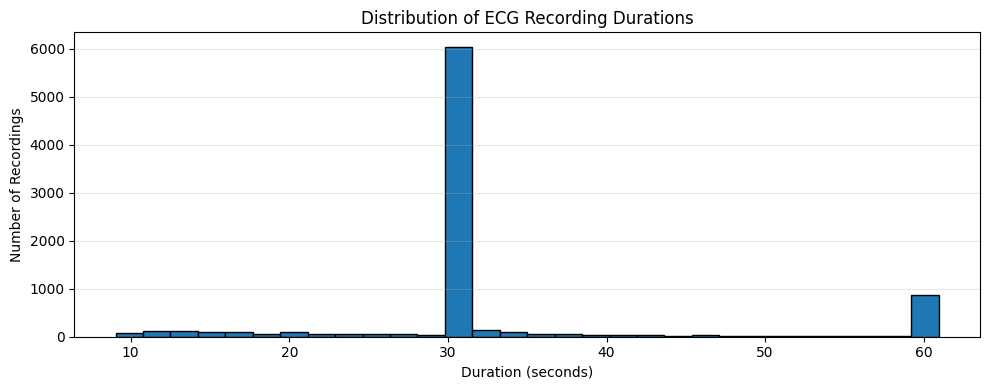

In [ ]:
# Summarize and visualize ECG recording durations
duration_summary = (
    quality_df
    .groupby("label")["duration_sec"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(2)
)
display(duration_summary)
plt.figure(figsize=(10, 4))
plt.hist(
    quality_df["duration_sec"].dropna(),
    bins=30,
    edgecolor="black"
)
plt.title("Distribution of ECG Recording Durations")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Recordings")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Note:** Observation: Most ECG recordings are around 30 seconds long, while some last about 60 seconds. The recording durations range from approximately 9 to 61 seconds. The Other class has the longest average duration (34.39 seconds), while the Noisy class has the shortest (24.22 seconds).

In [ ]:
# Identify and Review Invalid ECG Recordings
problematic = quality_df[
    quality_df["status"] != "valid"
]

display(problematic)

print("Problematic recordings:", len(problematic))


,record_id,label,status,n_samples,duration_sec,mean,std,min,max


Problematic recordings: 0


In [ ]:
# Filter and Retain Valid ECG Recordings
valid_ids = set(
    quality_df.loc[
        quality_df["status"] == "valid","record_id"
    ]
)
clean_labels = labels[
    labels["record_id"].isin(valid_ids)].copy()
clean_labels = clean_labels.reset_index(drop=True)
print("Original records:", len(labels))
print("Retained records:", len(clean_labels))
print("Excluded records:", len(labels) - len(clean_labels))
display(clean_labels["label"].value_counts())


Original records: 8528
Retained records: 8528
Excluded records: 0


,count
label,
N,5050
O,2456
A,738
~,284


## 5. ECG Signal Resampling
Reduce the sampling frequency of ECG recordings from 300 Hz to 150 Hz, following the CTRhythm preprocessing methodology.



In [ ]:
# Resample ECG Signals from 300 Hz to 150 Hz Using Linear Interpolation
def resample_ecg(signal, original_fs=300, target_fs=150):
    signal = np.asarray(signal, dtype=np.float64).flatten()
    new_positions = np.arange(
        0,
        len(signal),
        original_fs / target_fs
    )

    old_positions = np.arange(len(signal))
    resampled = np.interp(
        new_positions,
        old_positions,
        signal
    )
    return resampled

In [ ]:
# Test result
ecg_150 = resample_ecg(ecg)
print("Original length:", len(ecg))
print("Resampled length:", len(ecg_150))
print("Original duration:", len(ecg) / 300)
print("New duration:", len(ecg_150) / 150)

Original length: 9000
Resampled length: 4500
Original duration: 30.0
New duration: 30.0


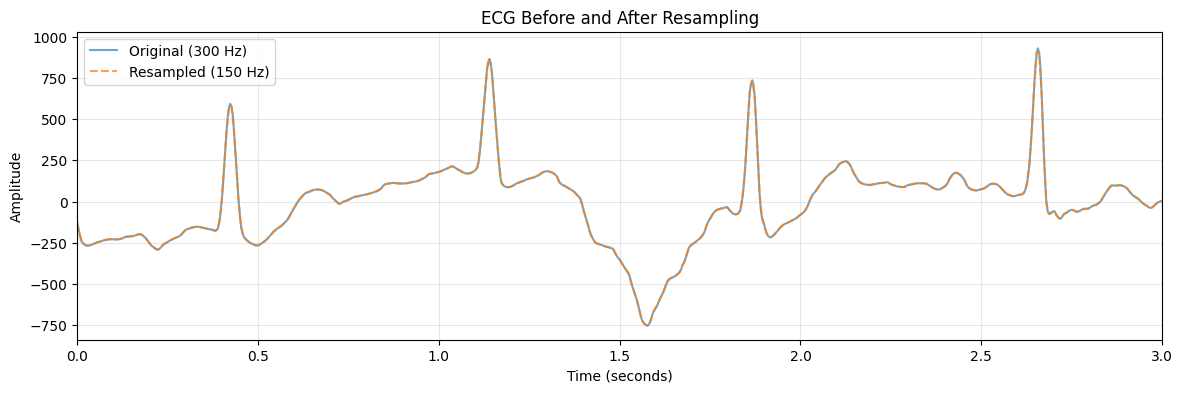

In [ ]:
# Visualize before and after resampling
time_300 = np.arange(len(ecg)) / 300
time_150 = np.arange(len(ecg_150)) / 150
plt.figure(figsize=(14, 4))
plt.plot(
    time_300, ecg,
    label="Original (300 Hz)",
    alpha=0.65
)
plt.plot(
    time_150, ecg_150,
    label="Resampled (150 Hz)",
    alpha=0.75,
    linestyle="--"
)
plt.xlim(0, min(3, len(ecg) / 300))
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Before and After Resampling")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Note:** After resampling from 300 Hz to 150 Hz, the number of sample was reduced by half while the recording duration stayed the same. Both waveforms look almost identical, showing that the main heartbeat patterns are still preserved. This helps reduce the amount of data and makes model training more efficient.


## 6. ECG Signal Normalization
Standardize ECG signal amplitudes to reduce variations in scale and offset between recordings.



In [ ]:
# Z-score normalization
from sklearn.preprocessing import scale
ecg_normalized = scale(ecg_150)
print("Before normalization:")
print("Mean:", np.mean(ecg_150))
print("Std:", np.std(ecg_150))
print("\nAfter normalization:")
print("Mean:", np.mean(ecg_normalized))
print("Std:", np.std(ecg_normalized))

Before normalization:
Mean: 18.557333333333332
Std: 168.28851826418688

After normalization:
Mean: 1.8947806286936004e-17
Std: 1.0


**Note:**  After applying Z-score normalization, the mean changed from 18.56 to nearly 0, while the standard deviation decreased from 168.29 to 1. This confirms that the ECG signal was successfully standardized, making its amplitude scale more consistent for model training.

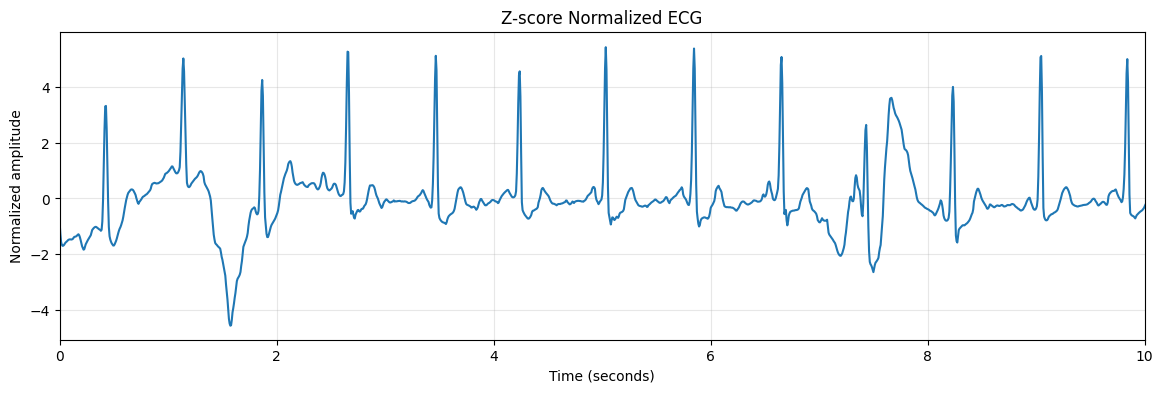

In [ ]:
# Plot the normalized waveform
time = np.arange(len(ecg_normalized)) / 150
plt.figure(figsize=(14, 4))
plt.plot(time, ecg_normalized)
plt.xlim(0, min(10, len(ecg_normalized) / 150))
plt.title("Z-score Normalized ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.grid(alpha=0.3)
plt.show()

**Note:** After applying Z-score normalization, we can see that the ECG signal still keeps its original heartbeat patterns, including the R-peaks and some unusual changes around 1.5 and 7.5 seconds. Only the amplitude scale has changed, while the waveform shape remains the same. This helps us keep the ECG signals on a consistent scale for model training.


## 7. Signal Length Standardization

Convert ECG recordings of different durations into fixed-length signals suitable for batch processing in the CTRhythm model.

In [ ]:
# Pad or truncate to 60 seconds
target_length = 150 * 60
def pad_or_truncate(signal, target_length=9000):
    result = np.zeros(target_length, dtype=np.float32)
    n = min(len(signal), target_length)
    result[:n] = signal[:n]
    return  result
ecg_final = pad_or_truncate(ecg_normalized)
print("Final signal shape:", ecg_final.shape)

Final signal shape: (9000,)


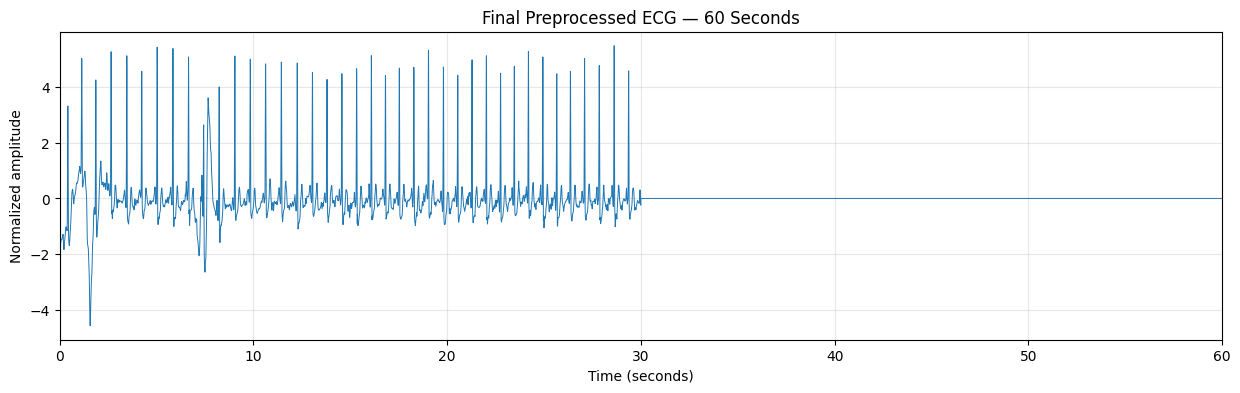

In [ ]:
# Visualize the final 60-second signal
time = np.arange(9000) / 150
plt.figure(figsize=(15,4))
plt.plot(time, ecg_final, linewidth=0.7)
plt.title("Final Preprocessed ECG — 60 Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.xlim(0, 60)
plt.grid(alpha=0.3)
plt.show()

**Note:** After preprocessing, the ECG signal has been standardized to 60 seconds (9,000 samples). The original 30-second recording keeps its heartbeat patterns, including the R-peaks, while the remaining 30 seconds are filled with zeros.

## 8. ECG Dataset Preprocessing

Apply the complete preprocessing pipeline to all valid ECG recordings, including resampling, Z-score normalization, and length standardization, to prepare a consistent dataset for model training.


In [ ]:
# Create an ECG Preprocessing Function
def preprocess_ecg(signal,
                   original_fs=300,
                   target_fs=150,
                   duration=60):
    signal = np.asarray(signal, dtype=np.float64).squeeze()
    if signal.ndim != 1 or signal.size == 0:
        raise ValueError("Invalid signal dimensions")
    if not np.isfinite(signal).all():
        raise ValueError("Non-finite values detected")
    if signal.std() < 1e-8:
        raise ValueError("Flat or near-constant signal")
    # Resample
    if original_fs != target_fs:
        signal = np.interp(
            np.arange(
                0,
                len(signal),
                original_fs / target_fs
            ),
            np.arange(len(signal)),
            signal
        )
    # Z-score normalization
    signal = scale(signal)
    # Pad or truncate to 60 seconds
    target_length = int(target_fs * duration)
    result = np.zeros(target_length, dtype=np.float32)
    n = min(len(signal), target_length)
    result[:n] = signal[:n]
    return result

In [ ]:
# Test
test_signal = loadmat(
    data_dir / "A00001.mat"
)["val"].squeeze()
processed = preprocess_ecg(test_signal)
print("Original shape:", test_signal.shape)
print("Processed shape:", processed.shape)
print("Data type:", processed.dtype)
print("Has NaN:", np.isnan(processed).any())
print("Has Inf:", np.isinf(processed).any())
assert processed.shape == (9000,)
assert np.isfinite(processed).all()
print("Preprocessing test passed!")

Original shape: (9000,)
Processed shape: (9000,)
Data type: float32
Has NaN: False
Has Inf: False
Preprocessing test passed!


In [ ]:
# Apply preprocessing to all recordings

X = []
y = []
record_ids = []
failed = []
for i, row in clean_labels.iterrows():
    record_id = row["record_id"]
    label = row["class_id"]
    try:
        mat_path = data_dir / f"{record_id}.mat"
        raw_signal = loadmat(mat_path)["val"].squeeze()
        processed_signal = preprocess_ecg(raw_signal)
        X.append(processed_signal)
        y.append(label)
        record_ids.append(record_id)
    except (OSError, ValueError, KeyError, TypeError) as e:
        failed.append({
            "record_id": record_id,
            "reason": str(e)
        })
    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(clean_labels)} records")
X = np.stack(X).astype(np.float32)
y = np.array(y, dtype=np.int64)
record_ids = np.array(record_ids)
print("\nProcessing completed!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Record IDs shape:", record_ids.shape)
print("Failed recordings:", len(failed))

Processed 1000/8528 records
Processed 2000/8528 records
Processed 3000/8528 records
Processed 4000/8528 records
Processed 5000/8528 records
Processed 6000/8528 records
Processed 7000/8528 records
Processed 8000/8528 records

Processing completed!
X shape: (8528, 9000)
y shape: (8528,)
Record IDs shape: (8528,)
Failed recordings: 0


In [ ]:
# Validate the final preprocessed ECG dataset
print("Number of signals:", X.shape[0])
print("Samples per signal:", X.shape[1])
print("Data type:", X.dtype)
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Minimum amplitude:", X.min())
print("Maximum amplitude:", X.max())
print("\nClass distribution:")
print(Counter(y))
assert X.ndim == 2
assert X.shape[1] == 9000
assert len(X) == len(y) == len(record_ids)
assert np.isfinite(X).all()
print("\nAll structural validation tests passed!")

Number of signals: 8528
Samples per signal: 9000
Data type: float32
NaN values: 0
Infinite values: 0
Minimum amplitude: -29.72132
Maximum amplitude: 26.36689

Class distribution:
Counter({np.int64(0): 5050, np.int64(2): 2456, np.int64(1): 738, np.int64(3): 284})

All structural validation tests passed!


In [ ]:
# Verify ECG Normalization and Padding
quality_lookup = quality_df.set_index("record_id")
normalized_means = []
normalized_stds = []
padding_errors = 0
for i, record_id in enumerate(record_ids):
    original_n = int(
        quality_lookup.loc[record_id, "n_samples"])
    resampled_n = len(
        np.arange(0, original_n, 300 / 150)
    )
    valid_n = min(resampled_n, 9000)
    active_part = X[i, :valid_n]
    normalized_means.append(active_part.mean())
    normalized_stds.append(active_part.std())
    if valid_n < 9000:
        if not np.all(X[i, valid_n:] == 0):
            padding_errors += 1
print("Maximum absolute mean:",
      np.max(np.abs(normalized_means)))
print("Min active-signal std:",
      np.min(normalized_stds))
print("Max active-signal std:",
      np.max(normalized_stds))
print("Padding errors:", padding_errors)

Maximum absolute mean: 0.01447858
Min active-signal std: 0.9924408
Max active-signal std: 1.0049386
Padding errors: 0


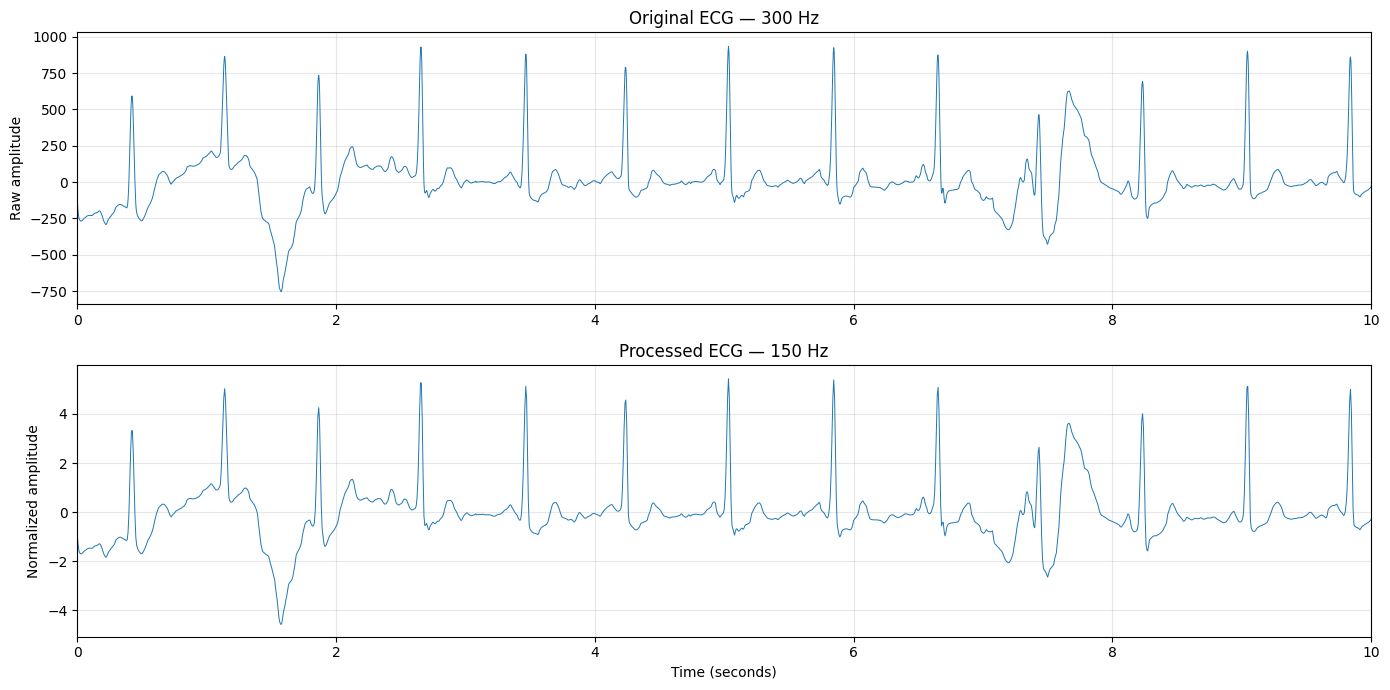

In [ ]:
# Compare the original andpProcessed ECG signals
example_id = record_ids[0]
raw = loadmat(
    data_dir / f"{example_id}.mat"
)["val"].squeeze()
final = X[0]
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(
    np.arange(len(raw)) / 300,
    raw,
    linewidth=0.7
)
axes[0].set_title("Original ECG — 300 Hz")
axes[0].set_xlim(0, min(10, len(raw) / 300))
axes[0].set_ylabel("Raw amplitude")
axes[0].grid(alpha=0.3)
axes[1].plot(
    np.arange(len(final)) / 150,
    final,
    linewidth=0.7
)
axes[1].set_title("Processed ECG — 150 Hz")
axes[1].set_xlim(0, 10)
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Normalized amplitude")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Note:** Comparing the first 10 seconds of the original and procesed ECG signals, we can see that the main R-peaks and heartbeat patterns are still preserved. Even though we reduced the sampling rate from 300 Hz to 150 Hz and normalized the amplitude, the overall waveform shape did not change much. This shows that we kept the main ECG features after preprocessing.

## 9. Preparing Data for CTRhythm Model Training

Convert the preprocessed ECG dataset into the tensor format required by the CNN–Transformer architecture and prepare the data for cross-validation.



In [ ]:
# Convert Data and Labels into PyTorch Tensors
X_tensor = torch.from_numpy(X).unsqueeze(1)
y_tensor = torch.from_numpy(y)
print("ECG tensor:", X_tensor.shape)
print("Label tensor:", y_tensor.shape)

ECG tensor: torch.Size([8528, 1, 9000])
Label tensor: torch.Size([8528])


In [ ]:
# Prepare 5-fold cross-validation
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
folds = list(skf.split(X, y))
for fold_num, (train_idx, val_idx) in enumerate(folds, 1):
    print(f"Fold {fold_num}")
    print("Training:", len(train_idx))
    print("Validation:", len(val_idx))
    print()

Fold 1
Training: 6822
Validation: 1706

Fold 2
Training: 6822
Validation: 1706

Fold 3
Training: 6822
Validation: 1706

Fold 4
Training: 6823
Validation: 1705

Fold 5
Training: 6823
Validation: 1705



In [ ]:
# Prepare DataLoader for training and validation
from torch.utils.data import TensorDataset, DataLoader
train_idx, val_idx = folds[0]
train_dataset = TensorDataset(
    X_tensor[train_idx],
    y_tensor[train_idx]
)
val_dataset = TensorDataset(
    X_tensor[val_idx],
    y_tensor[val_idx]
)
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)
batch_X, batch_y = next(iter(train_loader))
print("Batch signals:", batch_X.shape)
print("Batch labels:", batch_y.shape)


Batch signals: torch.Size([256, 1, 9000])
Batch labels: torch.Size([256])


In [ ]:
# Final DataLoader Validation
print("Batch shape:", batch_X.shape)
print("Label shape:", batch_y.shape)
print("Input dtype:", batch_X.dtype)
print("Label dtype:", batch_y.dtype)
print("Available classes:", torch.unique(y_tensor))
assert batch_X.shape[1:] == (1, 9000)
assert batch_X.dtype == torch.float32
assert y_tensor.dtype == torch.int64
assert torch.isfinite(batch_X).all()
assert torch.all((y_tensor >= 0) & (y_tensor < 4))
print("DataLoader validation passed!")

Batch shape: torch.Size([256, 1, 9000])
Label shape: torch.Size([256])
Input dtype: torch.float32
Label dtype: torch.int64
Available classes: tensor([0, 1, 2, 3])
DataLoader validation passed!
